# Spatial LR Correlation via Bivariate Moran's I (LIANA+)

**Companion notebook to `11_STARmapPLUS_BivariateMoransI.qmd`.** That Quarto doc's R chunks (`setup-r` -> `load-and-normalize` -> `export-for-python`) load the hippocampus-only STARmap PLUS Seurat object, log-normalize it, and export the pieces this notebook needs (expression matrix, coordinates, metadata, candidate LR pairs) to `starmap_plus_processed/starmap_hpc_export/`.

**Run the R notebook's export chunk first**, then run this notebook top to bottom using the `lianaPlus` conda environment as the Jupyter kernel.

This asks a simpler, more basic question than the vascular -> astrocyte -> microglia relay idea: for a given ligand-receptor pair, does high ligand expression at one location predict high receptor expression nearby, more than tissue-wide spatial autocorrelation alone would predict? That only needs expression + coordinates -- no cell-type identity, which conveniently sidesteps `10`'s still-unresolved cell-type vocabulary crosswalk between STARmap PLUS's own labels and the Jessberger/Visium-reference labels `06`-`08` used. Whatever pairs come out significant here are the ones worth stratifying by cell type afterward.

## Imports

In [1]:
import numpy as np
import pandas as pd
import scipy.io as sio
import anndata as ad
import scanpy as sc
import squidpy as sq
import liana as li
import matplotlib.pyplot as plt

/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx instead.
  warnings.warn(msg, FutureWarning)
/home/vkorob/miniconda3/envs/lianaPlus/lib/python3.10/site-packages/anndata/utils.py:434: 

## Build the AnnData object

`export_dir` below assumes this notebook lives in the same directory as the `.qmd` files (`multi-omic_CCC_analysys/`), matching the R chunk's `out_dir <- "starmap_plus_processed"`. Adjust the path if you move this notebook elsewhere.

In [2]:
export_dir = "starmap_plus_processed/starmap_hpc_export"

expr = sio.mmread(f"{export_dir}/expr_norm.mtx").tocsr().T  # genes x cells -> cells x genes for AnnData

genes = pd.read_csv(f"{export_dir}/genes.txt", header=None)[0].astype(str).tolist()
cells = pd.read_csv(f"{export_dir}/cells.txt", header=None)[0].astype(str).tolist()

coords = pd.read_csv(f"{export_dir}/coordinates.csv").set_index("cell_id").loc[cells]
meta   = pd.read_csv(f"{export_dir}/metadata.csv").set_index("cell_id").loc[cells]

print(f"Loaded {len(cells)} cells total, unfiltered (all samples/replicates/ages combined).")

Loaded 16278 cells total, unfiltered (all samples/replicates/ages combined).


## Choose which sample(s), replicate(s), or age(s) to analyze

By default this notebook pools all 4 samples together (whatever combination of replicate and age/timepoint the R export produced). The cell below auto-detects metadata columns that look like they identify sample, replicate, age, or timepoint, and prints their unique values so you know exactly what's available to filter on -- since the exact column names depend on what the R export chunk (`11_STARmapPLUS_BivariateMoransI.qmd`) wrote into `metadata.csv`, this is inspected rather than assumed.

The cell after that applies the actual filter (`selection_filter`, edit it there) -- leave it as `None` to keep the original all-samples-combined behavior. Filtering happens here, before `adata` is built, so every downstream cell (spatial neighbors graph, bivariate Moran's I, all the plots) automatically runs on just the subset you pick.

In [3]:
# Auto-detect metadata columns that look like sample/replicate/age/timepoint identifiers,
# and print their unique values -- so the filter below can be set against real column
# names/values instead of guessed ones.
candidate_keywords = ["sample", "replic", "age", "time", "slide", "batch", "group", "condition"]
candidate_cols = [c for c in meta.columns if any(k in c.lower() for k in candidate_keywords)]

if candidate_cols:
    print("Metadata columns that look like sample/replicate/age/timepoint identifiers:")
    for c in candidate_cols:
        print(f"\n'{c}' -- {meta[c].nunique(dropna=False)} unique value(s):")
        print(meta[c].value_counts(dropna=False))
else:
    print("No obvious sample/replicate/age/timepoint column found by name. Full column list:")
    print(meta.columns.tolist())

Metadata columns that look like sample/replicate/age/timepoint identifiers:

'biosample_id' -- 4 unique value(s):
biosample_id
ADmouse_11351_brain    4602
ADmouse_9707_brain     4075
ADmouse_9498_brain     3901
ADmouse_9735_brain     3700
Name: count, dtype: int64

'batch' -- 3 unique value(s):
batch
batch_4    8677
batch_2    3901
batch_1    3700
Name: count, dtype: int64

'time' -- 2 unique value(s):
time
13months    8503
8months     7775
Name: count, dtype: int64

'group' -- 1 unique value(s):
group
control    16278
Name: count, dtype: int64

'replicate' -- 2 unique value(s):
replicate
replicate_2    8677
replicate_1    7601
Name: count, dtype: int64


In [4]:
# ---- EDIT: choose which sample(s)/replicate(s)/age(s)/timepoint(s) to include ----
# Set to None to keep the original behavior (all 4 samples/replicates combined).
# Otherwise map one or more metadata column names (from the printout above) to the
# value(s) you want to keep -- multiple columns are combined with AND, e.g.:
#   selection_filter = {"sample": "Y_1"}
#   selection_filter = {"age": ["old"]}
#   selection_filter = {"sample": ["O_1", "O_2"], "age": ["old"]}
selection_filter = None

if selection_filter:
    mask = pd.Series(True, index=meta.index)
    for col, keep_vals in selection_filter.items():
        if col not in meta.columns:
            raise KeyError(f"'{col}' not in metadata columns: {meta.columns.tolist()}")
        keep_vals = keep_vals if isinstance(keep_vals, (list, tuple, set)) else [keep_vals]
        mask &= meta[col].isin(keep_vals)

    n_before = len(cells)
    mask_arr = mask.to_numpy()
    cells  = [c for c, keep in zip(cells, mask_arr) if keep]
    meta   = meta.loc[mask]
    coords = coords.loc[mask]
    expr   = expr.tocsr()[mask_arr]

    print(f"Filtered to {len(cells)}/{n_before} cells matching {selection_filter}.")
    if len(cells) == 0:
        raise RuntimeError("Filter matched 0 cells -- check the values against the printout in the cell above.")
else:
    print(f"No filter applied -- keeping all {len(cells)} cells (all samples/replicates/ages combined).")

No filter applied -- keeping all 16278 cells (all samples/replicates/ages combined).


In [5]:
adata = ad.AnnData(X=expr, obs=meta, var=pd.DataFrame(index=genes))
adata.obsm["spatial"] = coords[["spatial_1", "spatial_2"]].to_numpy()

adata

AnnData object with n_obs × n_vars = 16278 × 2766
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'NAME', 'biosample_id', 'donor_id', 'species', 'species__ontology_label', 'sex', 'disease', 'disease__ontology_label', 'organ', 'organ__ontology_label', 'library_preparation_protocol', 'library_preparation_protocol__ontology_label', 'orig_index', 'batch', 'time', 'group', 'replicate', 'label', 'region', 'region_merged', 'top_level_cell_type', 'sub_level_cell_type', 'celltype_merged'
    obsm: 'spatial'

## Choosing a bandwidth for the spatial neighbors graph

Switched from squidpy's `n_neighs=6` (a fixed-count KNN graph, borrowed from Visium's hex grid where every spot genuinely has 6 neighbors) to liana's own `li.ut.spatial_neighbors(..., kernel="gaussian", bandwidth=...)`. STARmap PLUS cells aren't on a regular grid, so a fixed neighbor *count* doesn't correspond to a fixed physical *distance* the way it does on Visium -- a Gaussian kernel with a bandwidth (a distance, in whatever units `adata.obsm["spatial"]` is in) is the more natural fit: weight decays smoothly with distance instead of a hard cutoff at a fixed rank.

The plot below is purely for calibrating that bandwidth before committing to it: it draws a circle of the given radius around a few example cells directly on the real coordinate density, and reports how many other cells actually fall inside it -- so "bandwidth=100" can be checked against something concrete (does that circle contain 3 cells or 300?) rather than picked blind. Call `plot_bandwidth_scale(...)` with a few different values before settling on one.

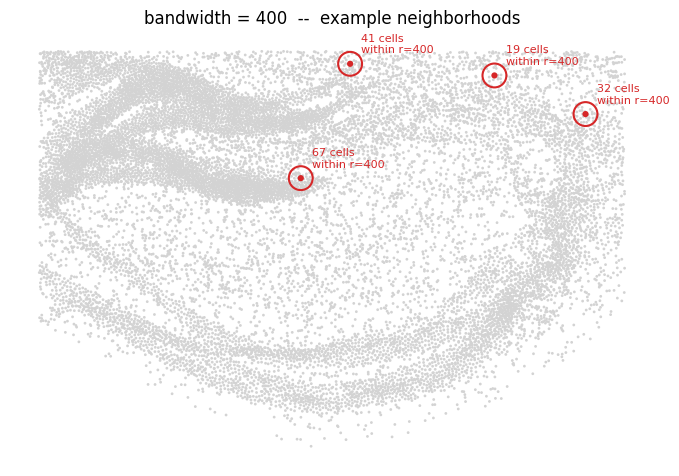

In [6]:
from matplotlib.patches import Circle

def plot_bandwidth_scale(bandwidth, n_examples=4, seed=0):
    """Visualize what a candidate Gaussian-kernel bandwidth (same spatial units as
    adata.obsm['spatial']) looks like against the real cell density: draws a circle of
    that radius around a few example cells and reports how many other cells actually
    fall inside each one -- a rough 'effective neighbor count' to compare against
    squidpy's old fixed n_neighs=6, so a bandwidth value means something concrete
    before it gets used."""
    coords = adata.obsm["spatial"]
    rng = np.random.default_rng(seed)
    example_idx = rng.choice(adata.n_obs, size=n_examples, replace=False)

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(coords[:, 0], coords[:, 1], color="lightgrey", s=4, edgecolors="none")

    for idx in example_idx:
        cx, cy = coords[idx]
        dist = np.sqrt((coords[:, 0] - cx) ** 2 + (coords[:, 1] - cy) ** 2)
        n_within = int((dist <= bandwidth).sum()) - 1  # exclude the point itself
        ax.add_patch(Circle((cx, cy), bandwidth, fill=False, edgecolor="#d62728", linewidth=1.5))
        ax.scatter([cx], [cy], color="#d62728", s=20, zorder=5, edgecolors="none")
        ax.annotate(f"{n_within} cells\nwithin r={bandwidth}", (cx, cy), textcoords="offset points",
                    xytext=(8, 8), fontsize=8, color="#d62728")

    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")
    ax.set_title(f"bandwidth = {bandwidth}  --  example neighborhoods")
    plt.tight_layout()
    plt.show()

plot_bandwidth_scale(bandwidth=400)

## Build the spatial neighbors graph (liana)

Pick a bandwidth from the calibration plot above (in the same units as `adata.obsm["spatial"]`), then build the actual graph `bivariate()` will use -- replacing the old `sq.gr.spatial_neighbors(adata, coord_type="generic", n_neighs=6)` call entirely.

`set_diag=True` gives every cell a self-loop (itself as its own neighbor, at distance 0 / weight 1). That's liana's own convention for this function, so it's kept as specified, but it's worth knowing it changes anything downstream that treats the graph as "my neighbors excluding me" -- e.g. the "Understanding the local score" section further down averages each cell's neighbors to illustrate the statistic, and with `set_diag=True` that average now includes the cell's own value too.

Also worth confirming rather than assuming: the later `li.mt.bivariate(..., connectivity_key="spatial_connectivities")` call was written when the graph came from squidpy, which uses that exact key name. liana's own `spatial_neighbors()` is a different function and hasn't actually been checked to write the same key -- the print below settles it before it can silently break.

In [7]:
li.ut.spatial_neighbors(adata, bandwidth=400, kernel="gaussian", set_diag=True)

print("obsp keys:", list(adata.obsp.keys()))
print("uns keys: ", list(adata.uns.keys()))
for k in adata.uns.keys():
    if "spatial" in k.lower() or "neighbor" in k.lower():
        print(f"uns['{k}']:", adata.uns[k])

obsp keys: ['spatial_connectivities']
uns keys:  []


## Run bivariate Moran's I across the candidate LR pairs

`lr_pairs.csv` is the full `sig_pairs_present` set from `10` (both ligand and receptor fully covered by the STARmap PLUS gene panel) -- not restricted to any assumed cell-type pair, this is a global, unbiased screen.

With `local_name` set (not `None` anymore), `li.mt.bivariate` returns something different than the global-only run did: an **AnnData**, not a plain DataFrame. `obs` = cells (same cells/order as `adata`), `var` = one row per LR pair holding the *global* stats (score + p-value), and `X` = the per-cell *local* score matrix (cells x pairs). The global-statistic argument is `global_name` (not `function_name`).

In [8]:
lr_pairs = pd.read_csv(f"{export_dir}/lr_pairs.csv")
interactions = list(zip(lr_pairs["ligand_complex"], lr_pairs["receptor_complex"]))

bivar_adata = li.mt.bivariate(
    adata,
    resource_name=None,
    interactions=interactions,
    global_name="morans",
    local_name="morans",
    connectivity_key="spatial_connectivities",
    n_perms=200,
    mask_negatives=False,   # whether to mask LowLow/NegativeNegative interactions
    add_categories=True,    # whether to add local categories to the results
    nz_prop=0,
    seed=1337,
    use_raw=False,
    verbose=False,
)

bivar_adata

AnnData object with n_obs × n_vars = 16278 × 12
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'NAME', 'biosample_id', 'donor_id', 'species', 'species__ontology_label', 'sex', 'disease', 'disease__ontology_label', 'organ', 'organ__ontology_label', 'library_preparation_protocol', 'library_preparation_protocol__ontology_label', 'orig_index', 'batch', 'time', 'group', 'replicate', 'label', 'region', 'region_merged', 'top_level_cell_type', 'sub_level_cell_type', 'celltype_merged'
    var: 'ligand', 'receptor', 'ligand_means', 'ligand_props', 'receptor_means', 'receptor_props', 'morans', 'morans_pvals', 'mean', 'std'
    obsm: 'spatial'
    layers: 'cats', 'pvals'
    obsp: 'spatial_connectivities'

## Inspect the returned results

`bivar_adata.var` holds the global stats (one row per LR pair) -- pull it into `global_scores` as a plain DataFrame so the rest of the notebook (built when this was global-only) keeps working unchanged. Also confirm `bivar_adata`'s cells are in the same order as `adata`'s, since the local-score plots below index `bivar_adata` and `adata`/`adata.obsm["spatial"]` side by side and that alignment is load-bearing.

In [9]:
assert list(bivar_adata.obs_names) == list(adata.obs_names), (
    "bivar_adata's cell order doesn't match adata's -- reindex before using local scores spatially."
)

global_scores = bivar_adata.var.copy()
print("columns:", global_scores.columns.tolist())
print("shape:", global_scores.shape)
global_scores.head()

columns: ['ligand', 'receptor', 'ligand_means', 'ligand_props', 'receptor_means', 'receptor_props', 'morans', 'morans_pvals', 'mean', 'std']
shape: (12, 10)


,ligand,receptor,ligand_means,ligand_props,receptor_means,receptor_props,morans,morans_pvals,mean,std
interaction,,,,,,,,,,
Igfbpl1^Dcc,Igfbpl1,Dcc,0.028763,0.007802,0.110224,0.029303,0.000359,0.635,0.000841,0.151217
Bsg^Slc16a7,Bsg,Slc16a7,1.793665,0.416759,0.168924,0.044354,-0.005462,0.000,-0.011001,0.241274
Ptn^Ptprz1,Ptn,Ptprz1,0.102669,0.026232,0.307689,0.078449,0.001931,0.005,0.004165,0.155685
Cxcl12^Itgb1,Cxcl12,Itgb1,0.552602,0.130606,0.345569,0.086067,-0.004560,0.000,-0.009067,0.246037
Ptn^Ptprs,Ptn,Ptprs,0.102669,0.026232,1.098622,0.279457,-0.001915,0.030,-0.003690,0.218277


## Is there a significance test for the local score?

As used so far, `local_score` is just a raw magnitude -- there's no indication of which cells' scores are stronger than spatial-random chance would produce, unlike the global result (which had `pval_col`). `add_categories=True` was set on the `bivariate()` call specifically to get something like a High-High/Low-Low/High-Low/Low-High classification (the standard LISA-style categorization, usually from thresholding standardized ligand/receptor values), and `n_perms=200` suggests permutation-based significance is computed *somewhere* -- but not yet confirmed where it landed for the *local* (per-cell) result specifically, as opposed to the global one. Check `bivar_adata`'s other slots before trusting raw score magnitude as if it were already significance-filtered.

In [10]:
print("layers:", list(bivar_adata.layers.keys()))
print("obsm:  ", list(bivar_adata.obsm.keys()))
print("obsp:  ", list(bivar_adata.obsp.keys()))
print("uns:   ", list(bivar_adata.uns.keys()))
print("var columns (already seen above):", bivar_adata.var.columns.tolist())

# If a "cats" (or similarly named) layer showed up above, this shows what it actually
# contains for one pair -- adjust the key once we see the real name.
for key in bivar_adata.layers:
    sample = np.asarray(bivar_adata.layers[key][:, 0]).reshape(-1)[:10]
    print(f"\nlayers['{key}'] sample (first pair, first 10 cells): {sample}")

layers: ['cats', 'pvals']
obsm:   ['spatial']
obsp:   ['spatial_connectivities']
uns:    []
var columns (already seen above): ['ligand', 'receptor', 'ligand_means', 'ligand_props', 'receptor_means', 'receptor_props', 'morans', 'morans_pvals', 'mean', 'std']

layers['cats'] sample (first pair, first 10 cells): [<16278x1 sparse matrix of type '<class 'numpy.int64'>'
 	with 10436 stored elements in Compressed Sparse Row format>]

layers['pvals'] sample (first pair, first 10 cells): [<16278x1 sparse matrix of type '<class 'numpy.float64'>'
 	with 16199 stored elements in Compressed Sparse Row format>]


## Global Moran's I summary, ranked by pair

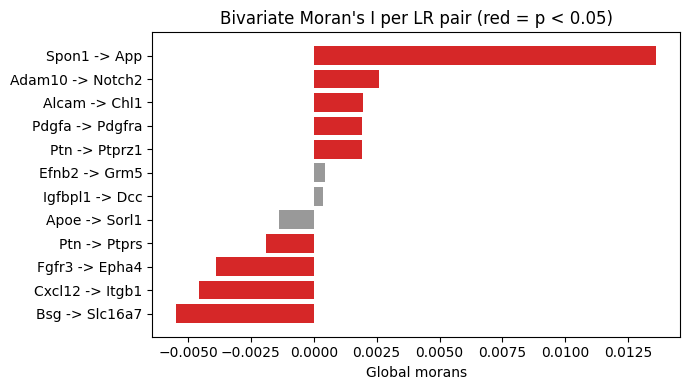

In [11]:
score_col = next((c for c in global_scores.columns if "morans" in c.lower() and "pval" not in c.lower()), None)
pval_col  = next((c for c in global_scores.columns if "pval" in c.lower()), None)
if score_col is None:
    raise RuntimeError(f"Could not find a Moran's I score column. Columns present: {global_scores.columns.tolist()}")

pair_label = global_scores["ligand"].astype(str) + " -> " + global_scores["receptor"].astype(str)
plot_df = global_scores.assign(pair_label=pair_label).sort_values(score_col, ascending=False)
sig_mask = (plot_df[pval_col] < 0.05) if pval_col else pd.Series(False, index=plot_df.index)

fig, ax = plt.subplots(figsize=(7, max(4, 0.3 * len(plot_df))))
ax.barh(plot_df["pair_label"], plot_df[score_col], color=["#d62728" if s else "#999999" for s in sig_mask])
ax.invert_yaxis()
ax.set_xlabel(f"Global {score_col}")
ax.set_title("Bivariate Moran's I per LR pair" + (" (red = p < 0.05)" if pval_col else ""))
plt.tight_layout()
plt.show()

## Ligand & receptor expression in space -- all significant, positive pairs by Moran's I

This plots actual gene expression (log-normalized, from `adata`), not the local Moran's I statistic itself -- that's still pending `local_name` (see the placeholder section below). For a multi-subunit complex (genes joined by `_`), expression is the mean across subunits, matching this project's `split_complex()` convention from `10`. Every pair with a significant global Moran's I (`pval_col < 0.05`) **and a positive score** gets its own row below. Negative-score pairs are dropped deliberately: this analysis works from the assumption that a genuine ligand-receptor relationship colocalizes (High-High), so a significant *negative* global Moran's I -- ligand and receptor tending to sit apart from each other in space -- isn't the kind of hit being screened for here, and gets excluded rather than plotted. This can still produce a lot of subplots (and take a while) if many pairs pass both filters.

5/12 pairs significant at p < 0.05 with positive global morans (4 significant-but-negative pair(s) excluded).
Plotting 16278 cells.
pair_expr built: 0.0s
Spon1 -> App: 0/16278 cells (0.0%) have NaN local score
Adam10 -> Notch2: 0/16278 cells (0.0%) have NaN local score
Alcam -> Chl1: 0/16278 cells (0.0%) have NaN local score
Pdgfa -> Pdgfra: 0/16278 cells (0.0%) have NaN local score
Ptn -> Ptprz1: 0/16278 cells (0.0%) have NaN local score
scatter + colorbars built: 1.0s


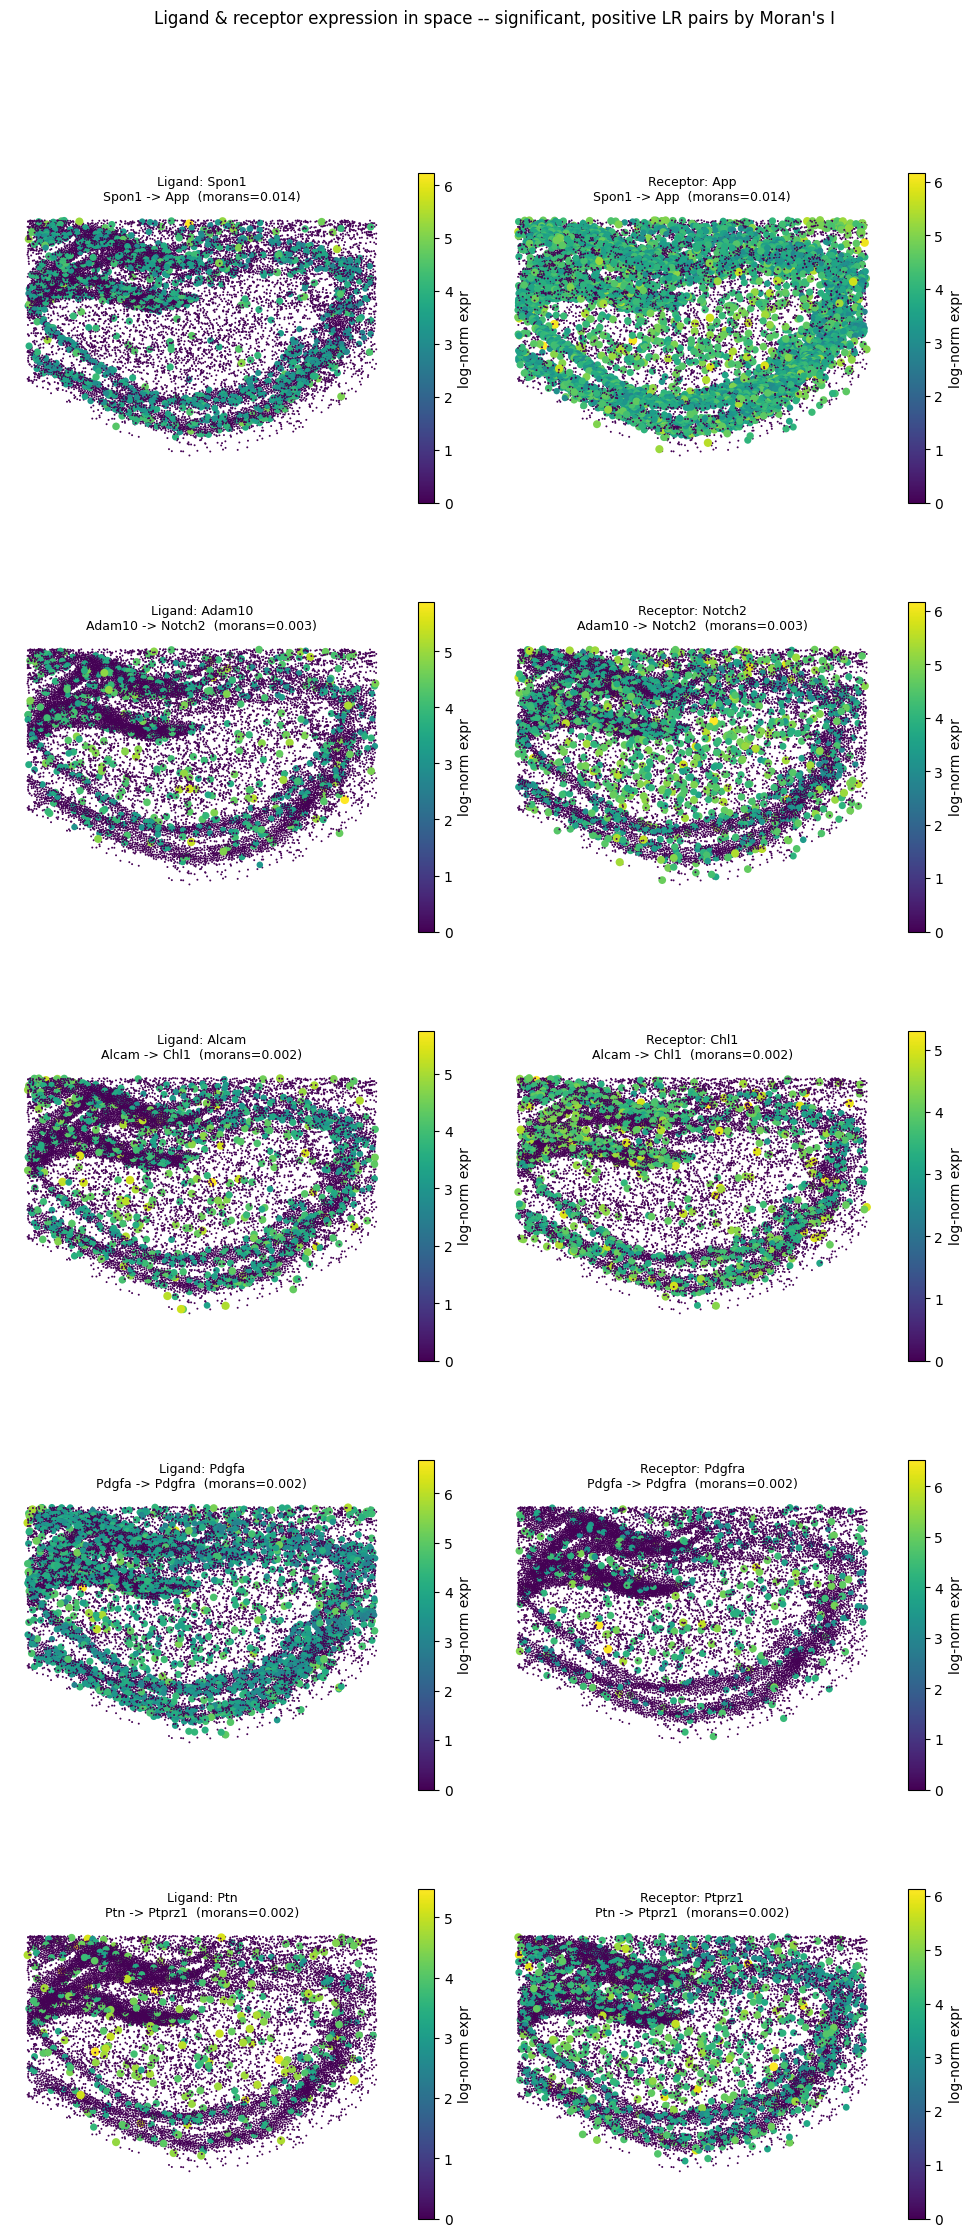

plt.show() (actual render): 4.1s


In [12]:
import time

def complex_expression(complex_str):
    """Mean log-normalized expression across a complex's subunit genes (genes joined by '_', if any)."""
    genes = [g for g in complex_str.split("_") if g in adata.var_names]
    if len(genes) == 0:
        return None
    vals = adata[:, genes].X
    vals = np.asarray(vals.todense()) if hasattr(vals, "todense") else np.asarray(vals)
    return vals.mean(axis=1)

def to_float_array(vals):
    """Robustly convert whatever bivar_adata[:, pair_id].X returns into a plain float array
    with real np.nan for anything missing/non-numeric. Defensive against two likely causes
    of the raw values not already being clean floats: (1) a still-sparse matrix, where
    np.asarray(...) on it does NOT densify -- it wraps the whole sparse object in a 0-d
    object array instead, and (2) pandas nullable NA sentinels from liana-py's masking
    (add_categories / nz_prop / mask_negatives), which plain np.isnan() can't handle."""
    if hasattr(vals, "toarray"):
        vals = vals.toarray()
    elif hasattr(vals, "todense"):
        vals = vals.todense()
    flat = np.asarray(vals).reshape(-1)
    return pd.to_numeric(pd.Series(flat), errors="coerce").to_numpy(dtype=float)

def size_from_values(values, min_s=2, max_s=40):
    """Scale point size by value, so low/zero-expression cells shrink toward invisible and only genuinely high values stand out."""
    values = np.asarray(values, dtype=float)
    vmax = np.nanmax(values)
    vmax = vmax if vmax > 0 else 1
    return min_s + (max_s - min_s) * np.clip(values / vmax, 0, 1)

def top_n_idx(score, n):
    """Indices of the n highest values, treating NaN as the lowest possible (never selected).
    Plain np.argsort puts NaN at the END of the sort order, so argsort(score)[-n:] silently
    grabs NaN-masked cells instead of the real top values whenever any NaNs are present."""
    score = np.asarray(score, dtype=float)
    score_safe = np.where(np.isnan(score), -np.inf, score)
    return np.argsort(score_safe)[-n:]

# All pairs with a significant AND positive global Moran's I -- negative-score pairs are
# excluded on purpose. A real ligand-receptor relationship is assumed to colocalize
# (High-High), so a significant *negative* score (ligand and receptor spatially apart)
# doesn't fit that assumption and isn't what this screen is looking for.
sig_alpha = 0.05
if pval_col:
    sig_pairs = plot_df[(plot_df[pval_col] < sig_alpha) & (plot_df[score_col] > 0)].copy()
    if sig_pairs.empty:
        print(f"No pairs significant at p < {sig_alpha} with a positive global {score_col} -- "
              "falling back to the single top pair by score so the notebook still runs.")
        sig_pairs = plot_df.head(1)
    else:
        n_sig_total = int((plot_df[pval_col] < sig_alpha).sum())
        n_dropped_negative = n_sig_total - len(sig_pairs)
        print(f"{len(sig_pairs)}/{len(plot_df)} pairs significant at p < {sig_alpha} with positive global {score_col}"
              + (f" ({n_dropped_negative} significant-but-negative pair(s) excluded)." if n_dropped_negative else "."))
        if len(sig_pairs) > 15:
            print(f"That's a lot of pairs -- the plots below will be correspondingly large/slow ({len(sig_pairs)} rows each).")
else:
    print("No p-value column found in global_scores -- can't filter by significance; falling back to the single top pair by score.")
    sig_pairs = plot_df.head(1)

coords_xy = adata.obsm["spatial"]
print(f"Plotting {adata.n_obs} cells.")

# Compute each pair's ligand/receptor expression and real local Moran's I score once and
# reuse below -- this used to get recomputed independently in three separate cells.
_t0 = time.time()
pair_expr = [
    {
        "pair_id": pair_id,
        "row": row,
        "ligand": complex_expression(row["ligand"]),
        "receptor": complex_expression(row["receptor"]),
        "local_score": to_float_array(bivar_adata[:, pair_id].X),
    }
    for pair_id, row in sig_pairs.iterrows()
]
print(f"pair_expr built: {time.time() - _t0:.1f}s")

for pe in pair_expr:
    n_nan = int(np.isnan(pe["local_score"]).sum())
    n_total = len(pe["local_score"])
    print(f"{pe['row']['pair_label']}: {n_nan}/{n_total} cells ({n_nan/n_total:.1%}) have NaN local score"
          + (" -- check nz_prop/mask_negatives on the bivariate() call if this is most of the cells" if n_nan/n_total > 0.5 else ""))

_t1 = time.time()
fig, axes = plt.subplots(len(pair_expr), 2, figsize=(10, 4.5 * len(pair_expr)), squeeze=False)

for i, pe in enumerate(pair_expr):
    row = pe["row"]
    for j, (role, values) in enumerate([("Ligand", pe["ligand"]), ("Receptor", pe["receptor"])]):
        ax = axes[i][j]
        gene_col = "ligand" if role == "Ligand" else "receptor"
        pts = ax.scatter(
            coords_xy[:, 0], coords_xy[:, 1],
            c=values, cmap="viridis", s=size_from_values(values),
            edgecolors="none",  # drawing an outline per marker is what makes scatter slow at this point count,
                                # especially combined with a per-point size array -- this is the main fix.
        )
        ax.set_title(f"{role}: {row[gene_col]}\n{row['pair_label']}  ({score_col}={row[score_col]:.3f})", fontsize=9)
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")
        plt.colorbar(pts, ax=ax, shrink=0.7, label="log-norm expr")

plt.suptitle("Ligand & receptor expression in space -- significant, positive LR pairs by Moran's I", y=1.02)
plt.tight_layout()
print(f"scatter + colorbars built: {time.time() - _t1:.1f}s")
_t2 = time.time()
plt.show()
print(f"plt.show() (actual render): {time.time() - _t2:.1f}s")

## Which cell types dominate the colocalization?

Now using liana-py's real local Moran's I (`pe["local_score"]`) instead of the earlier same-cell-product proxy -- this is neighbor-aware. One nuance worth flagging honestly: local Moran's I is positive for BOTH "High-High" (ligand and receptor both elevated nearby -- what we actually want) and "Low-Low" (both low nearby) associations, so sorting by raw score can in principle pick up either. In practice High-High cells tend to dominate the top of the ranking since expression is right-skewed (most values near zero, so Low-Low cross-products cluster near zero too), but the categorical labels `add_categories=True` should have added (check `bivar_adata` for a categories layer/column) would let this be done precisely -- worth switching to once we've seen where liana-py put them.

**Calculation:** take the top `top_frac` (5%) of cells by local score, get each cell type's share of that group (`value_counts(normalize=True)`), and divide by its tissue-wide share. Fold enrichment > 1 (right of the dashed line) = overrepresented among high-colocalization cells; < 1 = underrepresented.

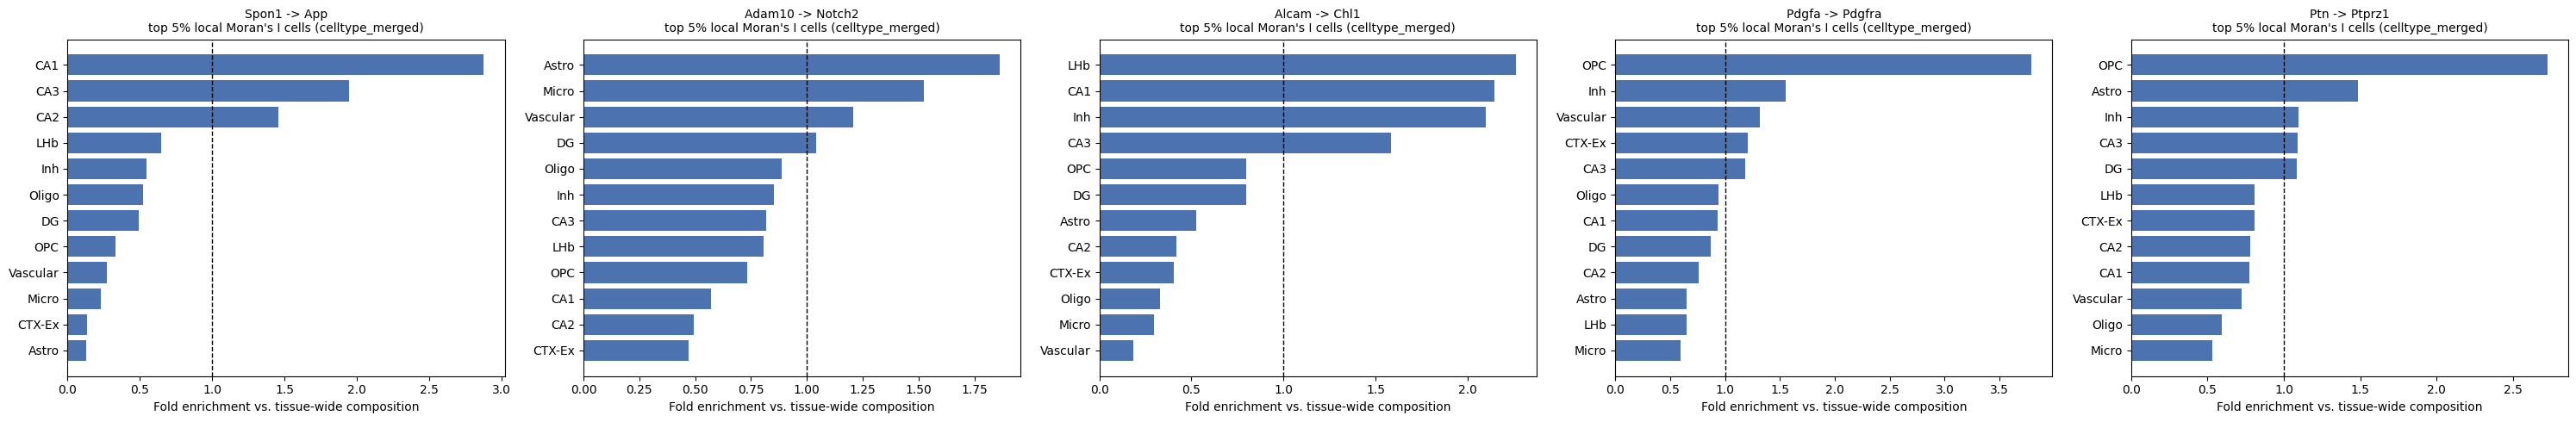

In [13]:
top_frac = 0.05  # top 5% of cells by local Moran's I score
celltype_col = "celltype_merged" if "celltype_merged" in adata.obs.columns else "top_level_cell_type"

fig, axes = plt.subplots(1, len(pair_expr), figsize=(6 * len(pair_expr), 5), squeeze=False)

for i, pe in enumerate(pair_expr):
    row = pe["row"]
    coloc_score = pe["local_score"]

    n_top = max(1, int(top_frac * len(coloc_score)))
    top_idx = top_n_idx(coloc_score, n_top)

    top_counts = adata.obs[celltype_col].iloc[top_idx].value_counts(normalize=True)
    bg_counts  = adata.obs[celltype_col].value_counts(normalize=True)
    enrichment = (top_counts / bg_counts).sort_values(ascending=False).dropna()

    ax = axes[0][i]
    ax.barh(enrichment.index.astype(str), enrichment.values, color="#4c72b0")
    ax.axvline(1, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("Fold enrichment vs. tissue-wide composition")
    ax.set_title(f"{row['pair_label']}\ntop {top_frac:.0%} local Moran's I cells ({celltype_col})", fontsize=10)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

### Sanity check: is this just baseline expression?

The fold-enrichment pattern above could simply reflect which cell types express the ligand/receptor at all, rather than anything about spatial colocalization specifically -- a cell type with near-zero baseline expression of either gene can't show up in a High-High hotspot no matter where it physically sits. Plotted below: tissue-wide mean expression (all cells, not just the top 5%) of each pair's ligand and receptor, per cell type. If a cell type is low here too, that's a straightforward baseline-expression explanation for its low enrichment above, rather than anything about the local statistic itself.

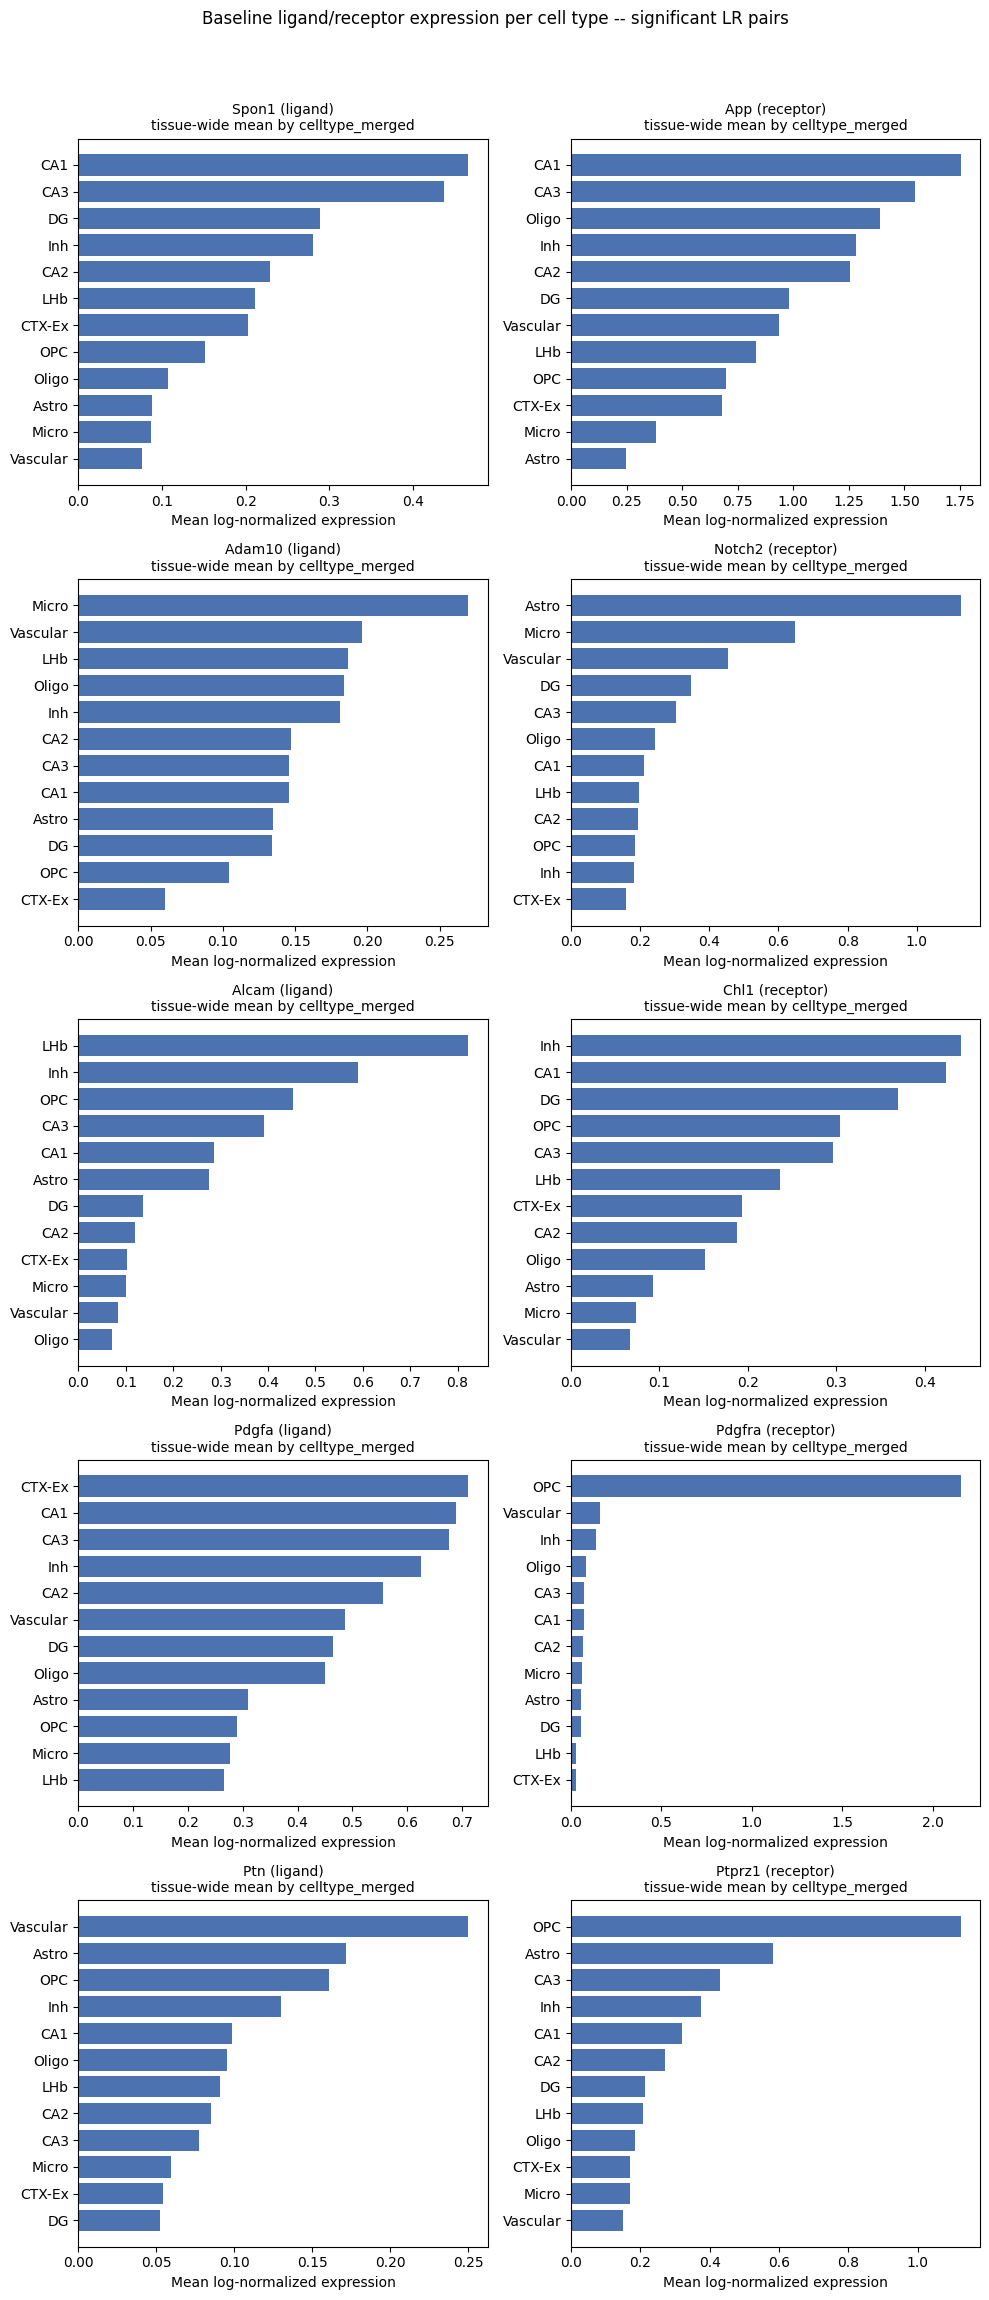

In [14]:
fig, axes = plt.subplots(len(pair_expr), 2, figsize=(10, 4.5 * len(pair_expr)), squeeze=False)

for i, pe in enumerate(pair_expr):
    row = pe["row"]
    by_type = pd.DataFrame({
        celltype_col: adata.obs[celltype_col].values,
        "ligand": pe["ligand"],
        "receptor": pe["receptor"],
    }).groupby(celltype_col, observed=True)[["ligand", "receptor"]].mean()

    for j, gene_role in enumerate(["ligand", "receptor"]):
        ax = axes[i][j]
        ordered = by_type[gene_role].sort_values(ascending=False)
        ax.barh(ordered.index.astype(str), ordered.values, color="#4c72b0")
        ax.set_xlabel("Mean log-normalized expression")
        ax.set_title(f"{row[gene_role]} ({gene_role})\ntissue-wide mean by {celltype_col}", fontsize=10)
        ax.invert_yaxis()

plt.suptitle("Baseline ligand/receptor expression per cell type -- significant LR pairs", y=1.02)
plt.tight_layout()
plt.show()

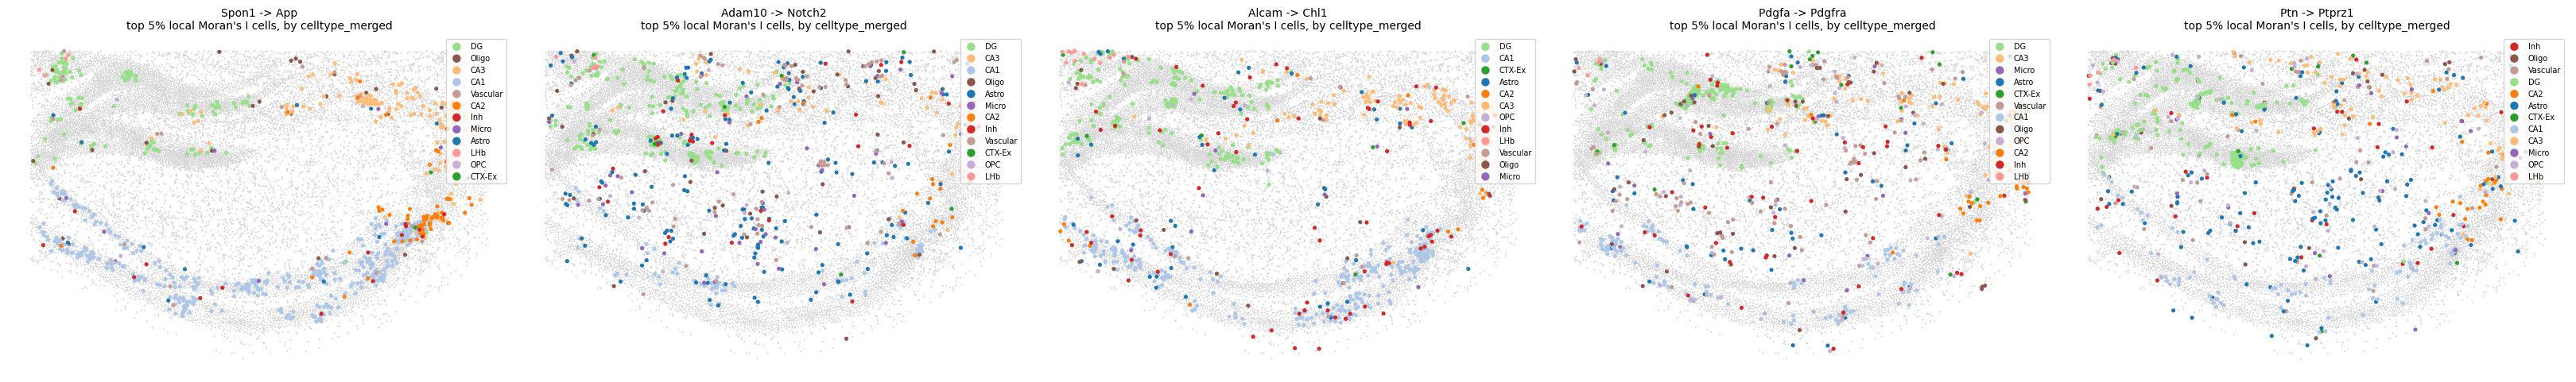

In [15]:
cell_types_all = sorted(adata.obs[celltype_col].dropna().unique().tolist())
cmap_ct = plt.get_cmap("tab20")
color_map = {ct: cmap_ct(i % 20) for i, ct in enumerate(cell_types_all)}

fig, axes = plt.subplots(1, len(pair_expr), figsize=(6.5 * len(pair_expr), 5.5), squeeze=False)

for i, pe in enumerate(pair_expr):
    row = pe["row"]
    coloc_score = pe["local_score"]
    n_top = max(1, int(top_frac * len(coloc_score)))
    top_idx = top_n_idx(coloc_score, n_top)

    ax = axes[0][i]
    ax.scatter(coords_xy[:, 0], coords_xy[:, 1], color="lightgrey", s=2, edgecolors="none")

    top_types = adata.obs[celltype_col].iloc[top_idx]
    for ct in top_types.unique():
        mask = (top_types == ct).values
        ax.scatter(coords_xy[top_idx][mask, 0], coords_xy[top_idx][mask, 1],
                   color=color_map[ct], s=14, label=str(ct), edgecolors="none")

    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")
    ax.set_title(f"{row['pair_label']}\ntop {top_frac:.0%} local Moran's I cells, by {celltype_col}", fontsize=10)
    ax.legend(markerscale=2, fontsize=7, loc="upper right", framealpha=0.8)

plt.tight_layout()
plt.show()

## Spatial maps of the local Moran's I score itself

Unlike the raw expression maps above, this plots the actual local bivariate statistic (`pe["local_score"]`) -- positive where ligand and receptor rise and fall together across neighboring cells (either both elevated, or both low), near zero where they don't track each other spatially. Diverging colormap centered at 0, since the score itself can be negative.

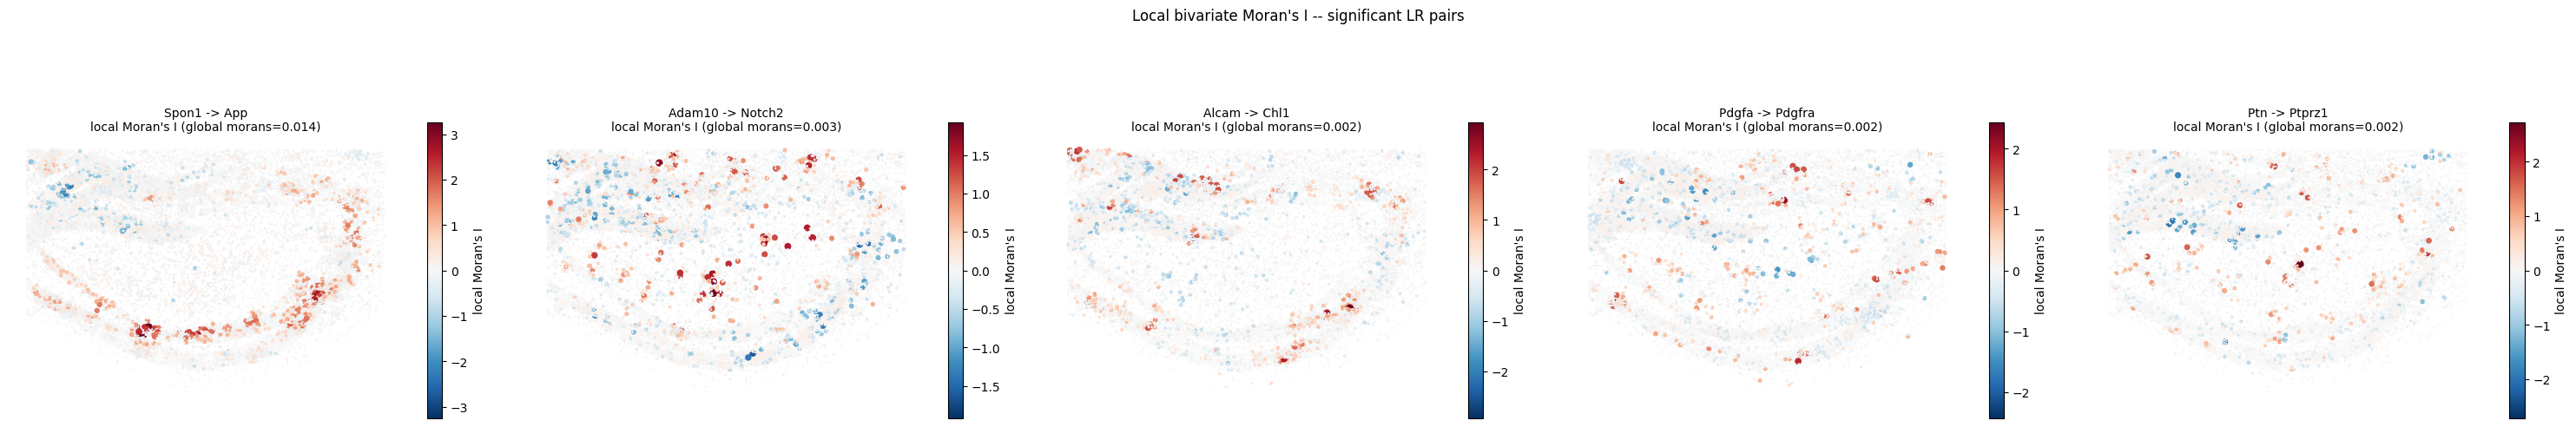

In [16]:
fig, axes = plt.subplots(1, len(pair_expr), figsize=(6 * len(pair_expr), 5.5), squeeze=False)

for i, pe in enumerate(pair_expr):
    row = pe["row"]
    values = pe["local_score"]
    vmax = np.nanmax(np.abs(values)) or 1

    ax = axes[0][i]
    pts = ax.scatter(
        coords_xy[:, 0], coords_xy[:, 1],
        c=values, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
        s=size_from_values(np.abs(values)), edgecolors="none",
    )
    ax.set_title(f"{row['pair_label']}\nlocal Moran's I (global {score_col}={row[score_col]:.3f})", fontsize=10)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")
    plt.colorbar(pts, ax=ax, shrink=0.7, label="local Moran's I")

plt.suptitle("Local bivariate Moran's I -- significant LR pairs", y=1.02)
plt.tight_layout()
plt.show()

## Manual look: Igfbpl1 -> Dcc

The three automated sections above (`453cea19`, `a6282855`, `cell-25`) only loop over `sig_pairs` -- pairs that passed the `p < 0.05` and positive-score filter. This section runs the exact same three analyses (cell-type dominance, baseline expression, local-score spatial map) for `Igfbpl1 -> Dcc` specifically, on demand, regardless of whether it happened to pass that filter -- reusing `complex_expression()`, `to_float_array()`, `top_n_idx()`, and `size_from_values()` already defined above, so this only works if the earlier cells in this notebook have already been run.

In [17]:
manual_ligand = "Igfbpl1"    # ---- EDIT: change these two to look up a different pair manually ----
manual_receptor = "Dcc"

manual_match = plot_df[(plot_df["ligand"] == manual_ligand) & (plot_df["receptor"] == manual_receptor)]

if manual_match.empty:
    close = plot_df[
        plot_df["ligand"].str.contains(manual_ligand, case=False, na=False)
        | plot_df["receptor"].str.contains(manual_receptor, case=False, na=False)
    ]
    raise RuntimeError(
        f"'{manual_ligand} -> {manual_receptor}' not found in plot_df (exact ligand/receptor match). "
        f"Check spelling/case, or whether it's part of a multi-subunit complex (genes joined by '_'). "
        f"Similar pairs found: {close['pair_label'].tolist() if not close.empty else 'none'}"
    )

manual_pair_id = manual_match.index[0]
manual_row = manual_match.iloc[0]

manual_pe = {
    "pair_id": manual_pair_id,
    "row": manual_row,
    "ligand": complex_expression(manual_row["ligand"]),
    "receptor": complex_expression(manual_row["receptor"]),
    "local_score": to_float_array(bivar_adata[:, manual_pair_id].X),
}

n_nan = int(np.isnan(manual_pe["local_score"]).sum())
n_total = len(manual_pe["local_score"])
print(f"{manual_row['pair_label']}: global {score_col} = {manual_row[score_col]:.4f}"
      + (f", p = {manual_row[pval_col]:.4g}" if pval_col else "")
      + f" | {n_nan}/{n_total} cells ({n_nan/n_total:.1%}) have NaN local score")

Igfbpl1 -> Dcc: global morans = 0.0004, p = 0.635 | 0/16278 cells (0.0%) have NaN local score


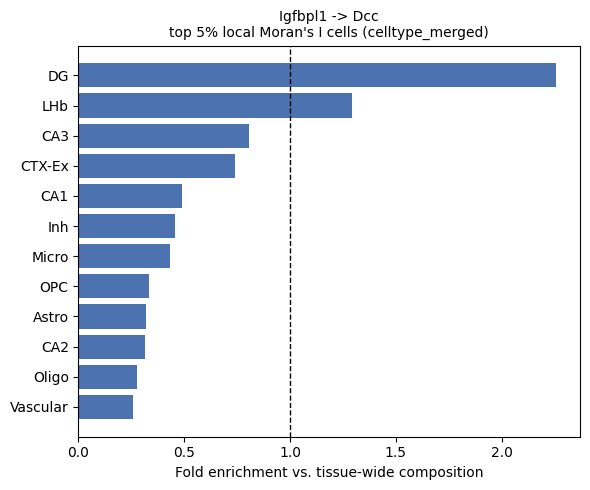

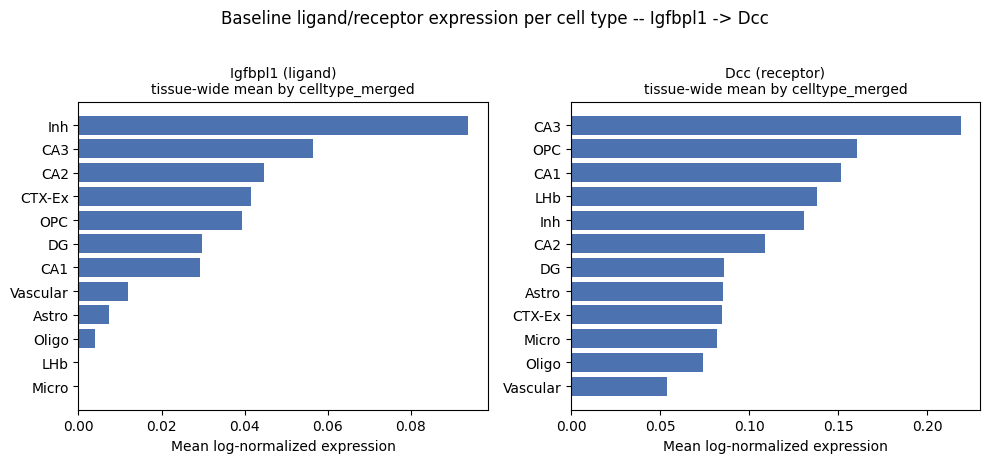

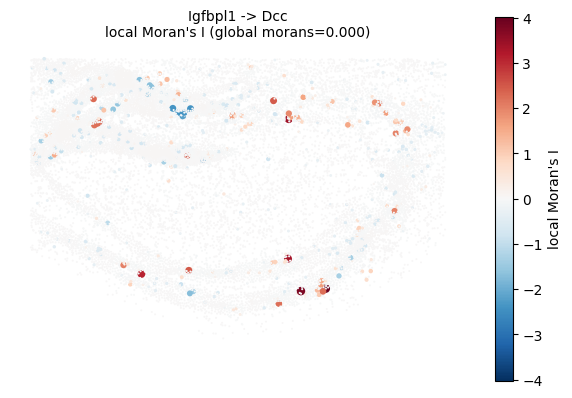

In [18]:
# 1) Which cell types dominate the colocalization -- same fold-enrichment calculation as 453cea19
n_top = max(1, int(top_frac * len(manual_pe["local_score"])))
top_idx = top_n_idx(manual_pe["local_score"], n_top)

top_counts = adata.obs[celltype_col].iloc[top_idx].value_counts(normalize=True)
bg_counts = adata.obs[celltype_col].value_counts(normalize=True)
enrichment = (top_counts / bg_counts).sort_values(ascending=False).dropna()

fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(enrichment.index.astype(str), enrichment.values, color="#4c72b0")
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Fold enrichment vs. tissue-wide composition")
ax.set_title(f"{manual_row['pair_label']}\ntop {top_frac:.0%} local Moran's I cells ({celltype_col})", fontsize=10)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# 2) Baseline ligand/receptor expression per cell type -- same calculation as a6282855
by_type = pd.DataFrame({
    celltype_col: adata.obs[celltype_col].values,
    "ligand": manual_pe["ligand"],
    "receptor": manual_pe["receptor"],
}).groupby(celltype_col, observed=True)[["ligand", "receptor"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for j, gene_role in enumerate(["ligand", "receptor"]):
    ax = axes[j]
    ordered = by_type[gene_role].sort_values(ascending=False)
    ax.barh(ordered.index.astype(str), ordered.values, color="#4c72b0")
    ax.set_xlabel("Mean log-normalized expression")
    ax.set_title(f"{manual_row[gene_role]} ({gene_role})\ntissue-wide mean by {celltype_col}", fontsize=10)
    ax.invert_yaxis()
plt.suptitle(f"Baseline ligand/receptor expression per cell type -- {manual_row['pair_label']}", y=1.02)
plt.tight_layout()
plt.show()

# 3) Spatial map of the local Moran's I score itself -- same calculation as cell-25
values = manual_pe["local_score"]
vmax = np.nanmax(np.abs(values)) or 1

fig, ax = plt.subplots(figsize=(6, 5.5))
pts = ax.scatter(
    coords_xy[:, 0], coords_xy[:, 1],
    c=values, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
    s=size_from_values(np.abs(values)), edgecolors="none",
)
ax.set_title(f"{manual_row['pair_label']}\nlocal Moran's I (global {score_col}={manual_row[score_col]:.3f})", fontsize=10)
ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
plt.colorbar(pts, ax=ax, shrink=0.7, label="local Moran's I")
plt.tight_layout()
plt.show()

### Why doesn't DG show up as red on the map above?

The raw-value map colors and sizes **every** cell by its literal local score, scaled to `vmax = max(|score|)` across the *whole tissue*. With a global Moran's I of only 0.006, almost every cell sits essentially at zero (pale color, near-minimum point size) -- the entire color/size range gets used up by whichever handful of cells happen to have the single largest magnitude anywhere in the section. DG's top-5% cells can be real and enriched in a *ranking* sense (higher than 95% of cells) while still being visually invisible next to those few extreme outliers: a modest, diffuse signal loses to a couple of dramatic points under a scale set by the single most extreme value in the whole dataset.

The panel below marks exactly the top-5% cutoff used for the fold-enrichment bar chart above and colors those cells by cell type (same view as the automated `f5c7252b` cell) instead of by raw score magnitude -- so DG's contribution is visible regardless of how small its absolute score is.

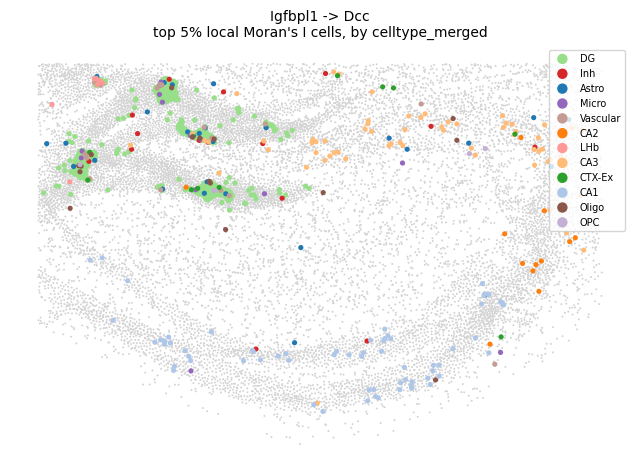

DG cells in top 5%: 559 cells, local score range [0.0355, 2.4429]
Tissue-wide local score range (all cells): [-2.4160, 4.0239]
If DG's max here is far below the tissue-wide max, that's the color/size scale saturating on a few non-DG outlier cells, not an absence of DG signal.


In [19]:
# Same top-5% cutoff as the fold-enrichment bar chart above, but plotted spatially and
# colored by cell type instead of by raw score magnitude -- same view as f5c7252b, for
# this manual pair. This is what actually shows where the enrichment is coming from.
n_top = max(1, int(top_frac * len(manual_pe["local_score"])))
top_idx = top_n_idx(manual_pe["local_score"], n_top)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(coords_xy[:, 0], coords_xy[:, 1], color="lightgrey", s=2, edgecolors="none")

top_types = adata.obs[celltype_col].iloc[top_idx]
for ct in top_types.unique():
    mask = (top_types == ct).values
    ax.scatter(coords_xy[top_idx][mask, 0], coords_xy[top_idx][mask, 1],
               color=color_map[ct], s=14, label=str(ct), edgecolors="none")

ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title(f"{manual_row['pair_label']}\ntop {top_frac:.0%} local Moran's I cells, by {celltype_col}", fontsize=10)
ax.legend(markerscale=2, fontsize=7, loc="upper right", framealpha=0.8)
plt.tight_layout()
plt.show()

# Also print DG's actual score range within that top-5% group, against the tissue-wide
# range -- puts a number on "modest but enriched" vs. "invisible on the raw-value map".
dg_mask_top = (top_types == "DG").values
if dg_mask_top.any():
    dg_scores_top = manual_pe["local_score"][top_idx][dg_mask_top]
    all_scores = manual_pe["local_score"]
    print(f"DG cells in top {top_frac:.0%}: {dg_mask_top.sum()} cells, "
          f"local score range [{dg_scores_top.min():.4f}, {dg_scores_top.max():.4f}]")
    print(f"Tissue-wide local score range (all cells): "
          f"[{np.nanmin(all_scores):.4f}, {np.nanmax(all_scores):.4f}]")
    print("If DG's max here is far below the tissue-wide max, that's the color/size scale "
          "saturating on a few non-DG outlier cells, not an absence of DG signal.")
else:
    print("No DG cells landed in the top 5% for this run.")

## Understanding the local score: one example, step by step

For the top-ranked pair, this breaks the local score into its ingredients: the ligand's own raw expression, the receptor's raw expression, the receptor's *spatially-lagged* value (the row-normalized average among each cell's neighbors -- the actual "neighbor" term the statistic multiplies against ligand), and finally liana-py's own local score. Watch for the pattern: local score should run high wherever ligand (panel 1) and neighbor-averaged receptor (panel 3) are elevated together.

Caveat: `receptor_lag` here is a simplified, illustrative reconstruction (plain row-normalized neighbor average) for building intuition -- it won't exactly reproduce liana-py's internal standardization/permutation machinery, so treat panel 3 as "roughly what's going on," not a literal derivation of panel 4.

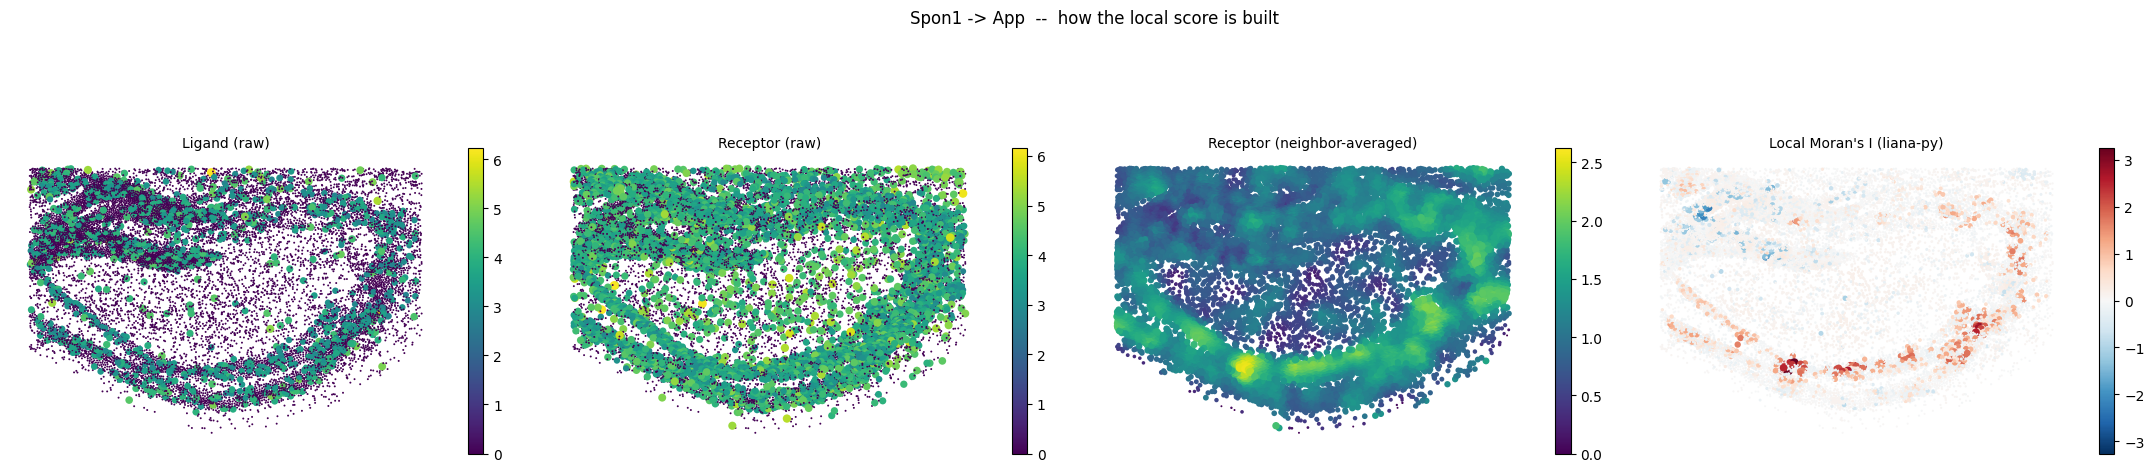

In [20]:
example = pair_expr[0]  # top-ranked pair by global Moran's I
row = example["row"]

W = adata.obsp["spatial_connectivities"]
row_sums = np.asarray(W.sum(axis=1)).flatten()
row_sums[row_sums == 0] = 1  # avoid divide-by-zero for any isolated cell
receptor_lag = np.asarray(W.dot(example["receptor"])).flatten() / row_sums

panels = [
    ("Ligand (raw)", example["ligand"], "viridis", False),
    ("Receptor (raw)", example["receptor"], "viridis", False),
    ("Receptor (neighbor-averaged)", receptor_lag, "viridis", False),
    ("Local Moran's I (liana-py)", example["local_score"], "RdBu_r", True),
]

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (title, values, cmap, diverging) in zip(axes, panels):
    if diverging:
        vmax = np.nanmax(np.abs(values)) or 1
        pts = ax.scatter(coords_xy[:, 0], coords_xy[:, 1], c=values, cmap=cmap,
                          vmin=-vmax, vmax=vmax, s=size_from_values(np.abs(values)), edgecolors="none")
    else:
        pts = ax.scatter(coords_xy[:, 0], coords_xy[:, 1], c=values, cmap=cmap,
                          s=size_from_values(values), edgecolors="none")
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")
    plt.colorbar(pts, ax=ax, shrink=0.7)

plt.suptitle(f"{row['pair_label']}  --  how the local score is built", y=1.05)
plt.tight_layout()
plt.show()

## Save results for downstream use

In [21]:
plot_df.to_csv(f"{export_dir}/bivariate_morans_global_summary.csv", index=False)

## Notes on interpretation

This screen deliberately runs on the whole hippocampus at once, not stratified by cell type -- a significant global Moran's I for a pair says the ligand and receptor spatially co-vary somewhere in the tissue, not which cell types are driving it. The natural next step for any pair that comes out significant is to overlay `celltype_merged` (from `10`) on the cells with the highest local scores in the spatial maps above, to see empirically which cell types are actually co-located there. That's what should inform whether a specific pair really looks like a vascular -> astrocyte or astrocyte -> microglia signal, rather than assuming the cell types up front.